# Chapter 6 — Advanced Logistic Regression and Extensions

**Sumber:** *scikit-learn Cookbook*, 3rd Ed. (John Sukup, Packt, 2025)

Regresi logistik adalah model klasifikasi linear yang paling banyak dipakai: cepat dilatih, menghasilkan **probabilitas** (bukan sekadar label), dan koefisiennya dapat ditafsirkan sebagai perubahan *log-odds*. Chapter ini memperluas regresi logistik biner ke kasus **multiclass** (One-vs-Rest dan multinomial/softmax), membahas **regularisasi L1/L2** untuk mengendalikan *overfitting* dan melakukan seleksi fitur, menerapkannya pada masalah **multilabel** (satu sampel dapat memiliki beberapa label sekaligus), dan menutup dengan **metrik evaluasi** klasifikasi: *accuracy*, *precision*, *recall*, *F1*, serta kurva ROC dan AUC.

**Daftar Isi**

1. 6.1 Gambaran Umum Regresi Logistik
2. 6.2 Teknik Klasifikasi Multiclass (One-vs-Rest vs Multinomial)
3. 6.3 Regularisasi pada Regresi Logistik (L2/Ridge dan L1/Lasso)
4. 6.4 Konsep Klasifikasi Multilabel
5. 6.5 Metrik Evaluasi Model
6. Latihan (Exercise 1–3)
7. Ringkasan Chapter 6

> **Catatan:** Notebook ini mereproduksi kode dari Chapter 6 (urutan resep sama dengan notebook resmi Packt), dengan penyesuaian agar berjalan di scikit-learn 1.9: (a) argumen `penalty='l1'/'l2'` sudah *deprecated* sejak 1.8 sehingga diganti dengan `l1_ratio=1` (L1) / `l1_ratio=0` (L2); (b) solver `liblinear` tidak lagi menangani multiclass secara otomatis, sehingga One-vs-Rest dibuat eksplisit dengan `OneVsRestClassifier`. Setiap resep dilengkapi penjelasan teori (**Teori:**) dan penafsiran hasil eksekusi (**Interpretasi:**).

## Import Library

In [1]:
%matplotlib inline
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import (load_breast_cancer, load_iris,
                              make_multilabel_classification, make_classification)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             precision_score, recall_score, f1_score, roc_curve, auc,
                             hamming_loss, log_loss)
from IPython.display import display

# Pengaturan tampilan gambar agar ukurannya moderat
plt.rcParams['figure.dpi'] = 90
sns.set_style('whitegrid')

def style_report(report_df):
    # Mewarnai classification report seperti pada notebook asli
    return (report_df
            .style
            .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
            .format({'precision': '{:.3f}', 'recall': '{:.3f}',
                     'f1-score': '{:.3f}', 'support': '{:.0f}'}))

print('numpy        :', np.__version__)
print('pandas       :', pd.__version__)
print('scikit-learn :', sklearn.__version__)

numpy        : 2.5.4
pandas       : 3.1.0
scikit-learn : 1.9.1


## 6.1 Gambaran Umum Regresi Logistik

**Teori:**

**Dari regresi linear ke probabilitas.** Pada klasifikasi biner $y\in\{0,1\}$ kita ingin memodelkan $p(\mathbf x)=P(y=1\mid\mathbf x)$. Kombinasi linear $z=\beta_0+\boldsymbol\beta^\top\mathbf x$ bisa bernilai berapa saja di $(-\infty,\infty)$, sehingga tidak dapat langsung dipakai sebagai probabilitas. Regresi logistik memasukkannya ke fungsi **sigmoid (logistik)**:

$$
p(\mathbf x) = \sigma(z) = \frac{1}{1+e^{-z}}, \qquad z = \beta_0 + \sum_{j=1}^{p}\beta_j x_j .
$$

Sigmoid memetakan $\mathbb R\to(0,1)$, simetris ($\sigma(-z)=1-\sigma(z)$), dan $\sigma(0)=0.5$.

**Log-odds (logit).** Membalik sigmoid memberikan

$$
\log\frac{p}{1-p} = \beta_0 + \boldsymbol\beta^\top\mathbf x ,
$$

jadi model ini **linear terhadap log-odds**. Tafsiran koefisien: menaikkan $x_j$ satu satuan (fitur lain tetap) menambah log-odds sebesar $\beta_j$, atau mengalikan *odds* dengan $e^{\beta_j}$ (*odds ratio*). Batas keputusan $p=0.5 \iff z=0$ adalah sebuah **hyperplane** — karena itu regresi logistik disebut klasifikator linear.

**Estimasi: maximum likelihood / log-loss.** Dengan $p_i=p(\mathbf x_i)$, parameter dipilih untuk meminimalkan *negative log-likelihood* (disebut juga *binary cross-entropy* atau *log-loss*):

$$
\mathcal L(\boldsymbol\beta) = -\sum_{i=1}^{n}\Big[y_i\log p_i + (1-y_i)\log(1-p_i)\Big].
$$

Fungsi ini **konveks**, tetapi tidak memiliki solusi tertutup seperti OLS; ia diselesaikan secara iteratif (Newton, L-BFGS, coordinate descent, SAG/SAGA). Gradiennya sederhana: $\nabla\mathcal L = X^\top(\mathbf p-\mathbf y)$. Jika data **terpisah sempurna** secara linear, likelihood terus naik saat $\lVert\boldsymbol\beta\rVert\to\infty$ sehingga estimasi tanpa penalti tidak konvergen — ini salah satu alasan scikit-learn **selalu memakai regularisasi L2 secara default** ($C=1$).

**Di scikit-learn.** `LogisticRegression` meminimalkan $\tfrac{1}{2}\lVert\boldsymbol\beta\rVert_2^2 + C\sum_i \ell(y_i,\mathbf x_i)$ dengan solver default `lbfgs`. Peringatan *ConvergenceWarning* muncul bila solver belum konvergen dalam `max_iter` iterasi, biasanya karena fitur tidak diskalakan — solusinya menaikkan `max_iter` (seperti di buku, `max_iter=10000`) atau, lebih baik, menstandardisasi fitur.

**Confusion matrix dan classification report.** Untuk kelas positif tertentu: TP, FP, FN, TN. *Precision* $=\frac{TP}{TP+FP}$ (dari yang diprediksi positif, berapa yang benar), *recall* $=\frac{TP}{TP+FN}$ (dari yang benar-benar positif, berapa yang tertangkap), *F1* = rata-rata harmonik keduanya. *Classification report* menampilkannya untuk tiap kelas, ditambah rata-rata *macro* (rata-rata biasa antar kelas) dan *weighted* (dibobot jumlah sampel/*support*).

**Dataset.** *Breast Cancer Wisconsin*: 569 sampel tumor, 30 fitur numerik hasil citra sel (radius, tekstur, perimeter, dll. — masing-masing *mean*, *standard error*, dan *worst*). Targetnya **0 = malignant (ganas), 1 = benign (jinak)**; perhatikan bahwa kelas "positif" (1) di scikit-learn adalah *benign*.

In [2]:
# Memuat dataset Breast Cancer
data = load_breast_cancer()
X = data.data
y = data.target

# Konversi ke DataFrame agar mudah dimanipulasi (opsional)
df = pd.DataFrame(X, columns=data.feature_names)
df['target'] = y
print('Ukuran data :', df.shape)
print('Distribusi kelas:', dict(zip(data.target_names.tolist(), np.bincount(y).tolist())))

# Membagi data latih dan uji (80:20)
X_train, X_test, y_train, y_test = train_test_split(df[data.feature_names],
                                                    df['target'],
                                                    test_size=0.2,
                                                    random_state=2024)

Ukuran data : (569, 31)
Distribusi kelas: {'malignant': 212, 'benign': 357}


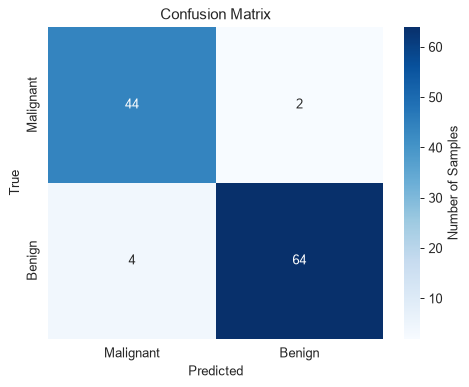

Accuracy: 0.95

Classification Report:


,precision,recall,f1-score,support
Malignant,0.917,0.957,0.936,46
Benign,0.970,0.941,0.955,68
accuracy,0.947,0.947,0.947,1
macro avg,0.943,0.949,0.946,114
weighted avg,0.948,0.947,0.948,114


In [3]:
# Membuat model Logistic Regression (max_iter dinaikkan agar konvergen pada fitur yang belum diskalakan)
model = LogisticRegression(max_iter=10000)

# Melatih model
model.fit(X_train, y_train)

# Prediksi
y_pred = model.predict(X_test)

# Evaluasi
accuracy = accuracy_score(y_test, y_pred)

# Confusion matrix
class_names = ['Malignant', 'Benign']
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names,
            cbar_kws={'label': 'Number of Samples'})
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Classification report sebagai DataFrame berwarna
report_dict = classification_report(y_test, y_pred, target_names=class_names, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()

print(f'Accuracy: {accuracy:.2f}\n')
print('Classification Report:')
display(style_report(report_df))

**Interpretasi:**

- Dataset berisi **569** sampel (212 *malignant*, 357 *benign*); data uji 20% = **114** sampel (46 malignant, 68 benign).
- Model mencapai **accuracy 0.95** (0.947). Dari confusion matrix: 44 dari 46 tumor ganas terdeteksi (*recall* malignant **0.957**), sementara 4 tumor jinak salah diprediksi ganas (*recall* benign 0.941). *Precision* malignant 0.917 berarti dari 48 prediksi "ganas", 44 benar.
- Secara medis, kesalahan paling berbahaya adalah *false negative* untuk kelas ganas (tumor ganas dikira jinak); di sini hanya 2 kasus. Kesalahan ke arah sebaliknya (4 kasus) "hanya" berujung pada pemeriksaan lanjutan.
- Rata-rata *macro* (0.946) dan *weighted* (0.948) hampir sama karena performa kedua kelas seimbang meskipun jumlah sampelnya tidak.

,coef (log-odds),odds ratio e^coef
mean radius,1.103,3.014
worst concavity,-1.011,0.364
texture error,0.758,2.135
worst compactness,-0.544,0.581
mean concavity,-0.453,0.636


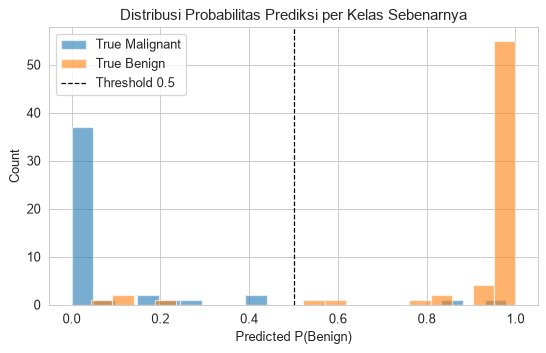

In [4]:
# Tambahan: odds ratio dari 5 koefisien dengan |beta| terbesar, dan sebaran probabilitas prediksi
coef = pd.Series(model.coef_[0], index=data.feature_names)
top = coef.reindex(coef.abs().sort_values(ascending=False).index)[:5]
display(pd.DataFrame({'coef (log-odds)': top.round(3), 'odds ratio e^coef': np.exp(top).round(3)}))

proba = model.predict_proba(X_test)[:, 1]
plt.figure(figsize=(7, 4))
for cls, name in enumerate(class_names):
    plt.hist(proba[y_test.values == cls], bins=20, alpha=0.6, label=f'True {name}')
plt.axvline(0.5, color='k', ls='--', lw=1, label='Threshold 0.5')
plt.xlabel('Predicted P(Benign)')
plt.ylabel('Count')
plt.title('Distribusi Probabilitas Prediksi per Kelas Sebenarnya')
plt.legend()
plt.show()

**Interpretasi:**

- Koefisien terbesar: `mean radius` (+1.10, *odds ratio* 3.01) dan `worst concavity` (−1.01, OR 0.36). Karena kelas 1 = benign, koefisien negatif berarti fitur tersebut **menurunkan** odds jinak (menaikkan risiko ganas) — cekungan sel yang dalam memang ciri keganasan.
- Hati-hati menafsirkan tanda: model ini dilatih pada fitur **tanpa standardisasi** dan banyak fitur sangat berkorelasi (radius, perimeter, area). Koefisien `mean radius` yang positif bertentangan dengan intuisi (tumor besar cenderung ganas), yang merupakan gejala klasik multikolinearitas — efeknya "dibagi" dengan fitur kembarannya. Odds ratio juga per satuan asli, sehingga tidak dapat dibandingkan antarfitur berskala berbeda.
- Histogram probabilitas memperlihatkan sebagian besar sampel diprediksi dengan keyakinan tinggi: ~37 tumor ganas di dekat P(benign) ≈ 0 dan ~55 tumor jinak di dekat 1. Namun beberapa kesalahan justru "yakin tapi salah" — ada tumor ganas dengan P(benign) > 0.85 dan tumor jinak dengan P(benign) < 0.15 — sehingga menggeser ambang saja tidak akan menangkap semuanya.

## 6.2 Teknik Klasifikasi Multiclass (One-vs-Rest vs Multinomial)

**Teori:**

Ketika ada $K>2$ kelas, regresi logistik biner harus diperluas. Dua strategi utama:

**1. One-vs-Rest (OvR / One-vs-All).** Latih $K$ klasifikator biner; klasifikator ke-$k$ memisahkan kelas $k$ (positif) dari semua kelas lain (negatif):

$$
p_k(\mathbf x) = \sigma(\beta_{k0} + \boldsymbol\beta_k^\top\mathbf x), \qquad \hat y = \arg\max_k\ p_k(\mathbf x).
$$

Karena tiap model dilatih terpisah, skor $p_k$ tidak otomatis berjumlah 1 (scikit-learn menormalkannya saat `predict_proba`). Kelebihan: sederhana, bisa dipakai dengan klasifikator biner apa pun, mudah diparalelkan. Kekurangan: setiap sub-masalah **tidak seimbang** (1 kelas vs $K-1$ kelas) dan skor antar-model tidak terkalibrasi bersama, sehingga ada daerah ruang fitur yang "ambigu".

**2. Multinomial (Softmax Regression).** Satu model dengan $K$ vektor koefisien yang dioptimasi **bersama-sama**:

$$
P(y=k\mid\mathbf x) = \frac{\exp(\beta_{k0}+\boldsymbol\beta_k^\top\mathbf x)}{\sum_{j=1}^{K}\exp(\beta_{j0}+\boldsymbol\beta_j^\top\mathbf x)},
\qquad
\mathcal L = -\sum_{i}\sum_{k} \mathbb 1[y_i=k]\log P(y_i=k\mid\mathbf x_i).
$$

Ini adalah *cross-entropy* multikelas. Probabilitas langsung konsisten (berjumlah 1), dan log-odds antara dua kelas adalah linear: $\log\frac{P(k)}{P(j)} = (\boldsymbol\beta_k-\boldsymbol\beta_j)^\top\mathbf x + \dots$. Untuk $K=2$ softmax tereduksi menjadi sigmoid. Multinomial umumnya menghasilkan probabilitas yang lebih terkalibrasi dan cocok bila kelas saling eksklusif.

**Di scikit-learn 1.9.** Solver `lbfgs`, `newton-cg`, `newton-cholesky`, `sag`, `saga` otomatis memakai **multinomial** untuk $K\ge3$. Parameter lama `multi_class='ovr'` sudah dihapus, dan `liblinear` (yang hanya mampu biner) kini menolak data multikelas — maka OvR dibuat eksplisit dengan `OneVsRestClassifier(LogisticRegression(solver='liblinear'))`, yang setara dengan perilaku buku.

**Strategi lain:** *One-vs-One* (`OneVsOneClassifier`) melatih $K(K-1)/2$ model untuk setiap pasangan kelas lalu melakukan *voting*.

**Dataset Iris:** 150 bunga, 4 fitur (panjang/lebar sepal dan petal), 3 spesies seimbang (50 per kelas). *Setosa* terpisah linear dari dua kelas lain, sedangkan *Versicolor* dan *Virginica* sedikit tumpang tindih.

In [5]:
# Memuat dataset Iris
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Membagi data (70:30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (105, 4)  Test: (45, 4)


In [6]:
# One-vs-Rest: liblinear dibungkus OneVsRestClassifier (setara solver='liblinear' di buku)
ovr_model = OneVsRestClassifier(LogisticRegression(solver='liblinear'))
ovr_model.fit(X_train, y_train)

# Multinomial (softmax) dengan lbfgs
multinomial_model = LogisticRegression(solver='lbfgs', max_iter=1000)
multinomial_model.fit(X_train, y_train)

# Prediksi
y_pred_ovr = ovr_model.predict(X_test)
y_pred_multinomial = multinomial_model.predict(X_test)

# Evaluasi OvR
accuracy_ovr = accuracy_score(y_test, y_pred_ovr)
report_ovr = pd.DataFrame(classification_report(y_test, y_pred_ovr, output_dict=True)).transpose()
print(f'One-vs-Rest (OvR) Logistic Regression  -- accuracy = {accuracy_ovr:.3f}')
display(style_report(report_ovr))

# Evaluasi Multinomial
accuracy_multinomial = accuracy_score(y_test, y_pred_multinomial)
report_multinomial = pd.DataFrame(classification_report(y_test, y_pred_multinomial, output_dict=True)).transpose()
print(f'Multinomial Logistic Regression  -- accuracy = {accuracy_multinomial:.3f}')
display(style_report(report_multinomial))

# Tambahan: kualitas probabilitas (log-loss, makin kecil makin baik)
print(f'Log-loss OvR         : {log_loss(y_test, ovr_model.predict_proba(X_test)):.4f}')
print(f'Log-loss Multinomial : {log_loss(y_test, multinomial_model.predict_proba(X_test)):.4f}')

One-vs-Rest (OvR) Logistic Regression  -- accuracy = 0.956


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.917,0.917,0.917,12
2,0.933,0.933,0.933,15
accuracy,0.956,0.956,0.956,1
macro avg,0.950,0.950,0.950,45
weighted avg,0.956,0.956,0.956,45


Multinomial Logistic Regression  -- accuracy = 0.933

,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.846,0.917,0.880,12
2,0.929,0.867,0.897,15
accuracy,0.933,0.933,0.933,1
macro avg,0.925,0.928,0.926,45
weighted avg,0.935,0.933,0.934,45


Log-loss OvR         : 0.3198
Log-loss Multinomial : 0.1726


**Interpretasi:**

- Data uji berisi 45 bunga (18 setosa, 12 versicolor, 15 virginica). *Setosa* diklasifikasikan sempurna oleh kedua model (precision = recall = 1.000), sesuai fakta bahwa kelas ini terpisah linear.
- **OvR** memperoleh accuracy **0.956** (2 kesalahan), **multinomial** **0.933** (3 kesalahan). Selisihnya hanya **satu sampel** pada data uji kecil, jadi bukan bukti bahwa OvR lebih baik. Semua kesalahan terjadi antara *versicolor* dan *virginica*.
- Dari sisi kualitas probabilitas, multinomial jauh lebih baik: **log-loss 0.173 vs 0.320**. Softmax mengoptimasi probabilitas ketiga kelas bersama-sama, sedangkan OvR menormalkan tiga sigmoid yang dilatih terpisah (ditambah liblinear juga meregularisasi intersep), sehingga probabilitasnya kurang tajam/terkalibrasi.

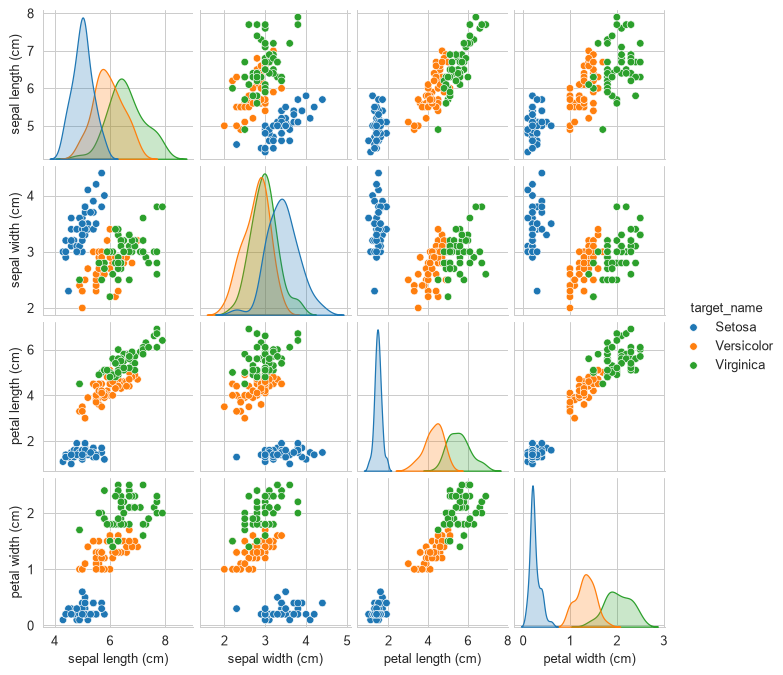

In [7]:
# Pairplot untuk melihat keterpisahan kelas
target_names = {0: 'Setosa', 1: 'Versicolor', 2: 'Virginica'}
df['target_name'] = df['target'].map(target_names)
sns.pairplot(df.drop(columns='target'), hue='target_name', diag_kind='kde', height=1.9)
plt.show()

**Interpretasi:**

- Pairplot menegaskan struktur Iris: pada fitur **petal length** dan **petal width** *Setosa* membentuk kelompok terpisah jauh, sedangkan *Versicolor* dan *Virginica* bersebelahan dengan sedikit tumpang tindih. Fitur sepal jauh kurang diskriminatif (kurva KDE ketiga kelas saling menumpuk).
- Inilah sebabnya model linear cukup untuk mencapai ~93–96% accuracy, dan kesalahan yang tersisa selalu berada di perbatasan versicolor–virginica.

One-vs-Rest (liblinear): test acc (2 fitur petal) = 0.844
Multinomial (lbfgs): test acc (2 fitur petal) = 0.911


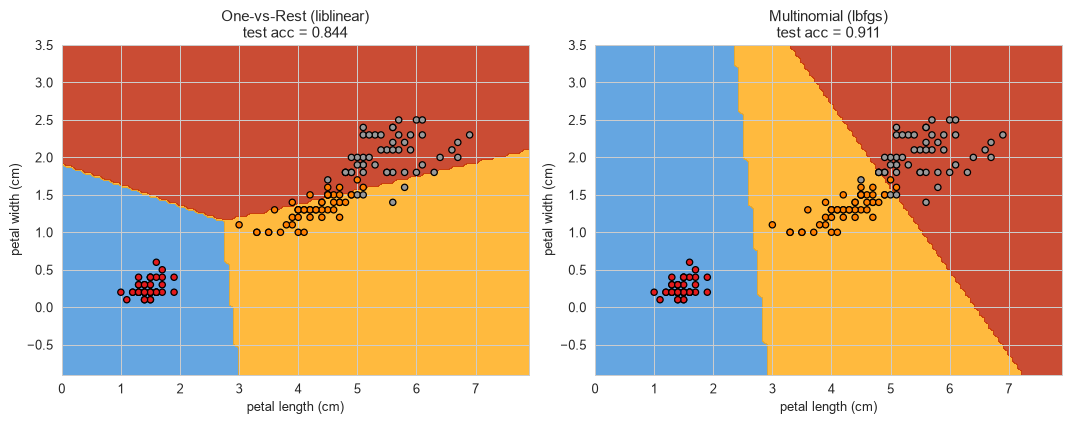

In [8]:
# Tambahan: batas keputusan OvR vs Multinomial pada 2 fitur petal (DecisionBoundaryDisplay diimpor di buku)
X2 = X[:, 2:4]
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.3, random_state=2024)
models2 = {'One-vs-Rest (liblinear)': OneVsRestClassifier(LogisticRegression(solver='liblinear')),
           'Multinomial (lbfgs)': LogisticRegression(max_iter=1000)}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (name, m) in zip(axes, models2.items()):
    m.fit(X2_train, y2_train)
    DecisionBoundaryDisplay.from_estimator(m, X2, response_method='predict',
                                           alpha=0.8, ax=ax, xlabel=feature_names[2], ylabel=feature_names[3])
    sc = ax.scatter(X2[:, 0], X2[:, 1], c=y, cmap='Set1', edgecolor='k', s=25)
    ax.set_title(f'{name}\ntest acc = {m.score(X2_test, y2_test):.3f}')
    print(f'{name}: test acc (2 fitur petal) = {m.score(X2_test, y2_test):.3f}')
plt.tight_layout()
plt.show()

**Interpretasi:**

- Dengan hanya 2 fitur petal, perbedaan kedua strategi tampak jelas. **Multinomial** membentuk tiga daerah yang dipisahkan garis lurus yang rapi, dengan batas versicolor–virginica miring mengikuti arah sebaran data → accuracy uji **0.911**.
- **OvR** menghasilkan batas yang "patah" dan daerah *virginica* (merah) yang terlalu luas di bagian atas, sehingga beberapa versicolor salah klasifikasi → accuracy **0.844**. Penyebabnya: klasifikator "versicolor vs rest" kesulitan karena versicolor terletak **di tengah** di antara dua kelas lain, sehingga tidak dapat dipisahkan oleh satu garis dari "rest". Ini contoh nyata kelemahan OvR yang disebut di bagian teori.

## 6.3 Regularisasi pada Regresi Logistik (L2/Ridge dan L1/Lasso)

**Teori:**

Regularisasi menambahkan penalti terhadap besarnya koefisien pada fungsi log-loss. Di scikit-learn penalti diparameterkan dengan **$C$ = kebalikan kekuatan regularisasi** (berbeda dengan $\alpha$ di `Ridge`/`Lasso` regresi):

$$
\text{L2 (Ridge):}\quad \min_{\boldsymbol\beta}\ \tfrac12\lVert\boldsymbol\beta\rVert_2^2 + C\sum_{i=1}^{n}\ell(y_i,\mathbf x_i),
\qquad
\text{L1 (Lasso):}\quad \min_{\boldsymbol\beta}\ \lVert\boldsymbol\beta\rVert_1 + C\sum_{i=1}^{n}\ell(y_i,\mathbf x_i),
$$

dengan $\ell$ adalah log-loss per sampel. **$C$ kecil → penalti kuat** (koefisien kecil, model sederhana, bias naik); **$C$ besar → penalti lemah** (mendekati MLE tanpa penalti, varians naik). Secara Bayesian, L2 setara dengan *prior* Gaussian pada koefisien dan L1 setara *prior* Laplace (MAP estimate).

- **L2** menyusutkan semua koefisien secara halus menuju nol tetapi hampir tidak pernah tepat nol; sangat membantu saat fitur saling berkorelasi (multikolinearitas) dan mencegah koefisien "meledak" pada data yang terpisah sempurna.
- **L1** menghasilkan **solusi sparse**: banyak koefisien tepat nol, sehingga sekaligus melakukan **seleksi fitur**. Penyebabnya geometris — daerah kendala $\lVert\boldsymbol\beta\rVert_1\le t$ berbentuk "berlian" bersudut, dan kontur log-loss cenderung menyentuhnya di sudut (sumbu). Di antara fitur yang sangat berkorelasi, L1 cenderung memilih satu secara agak acak.
- **Elastic-Net** menggabungkan keduanya (`l1_ratio` di antara 0 dan 1, hanya solver `saga`).

**API scikit-learn 1.9.** Argumen `penalty` *deprecated*; pemilihan jenis penalti kini lewat `l1_ratio`: `l1_ratio=0` → L2, `l1_ratio=1` → L1, $0<$ `l1_ratio` $<1$ → elastic-net, dan `C=np.inf` → tanpa penalti. Solver yang mendukung L1: `liblinear` dan `saga`.

**Standardisasi itu wajib.** Penalti memperlakukan semua koefisien setara, padahal besar koefisien bergantung pada skala fitur (fitur *area* bernilai ratusan–ribuan, *smoothness* sekitar 0.1). Tanpa `StandardScaler`, penalti akan "menghukum" fitur secara tidak adil. Scaler di-*fit* hanya pada data latih untuk mencegah *data leakage*.

**Coefficient path.** Memplot koefisien terhadap $C$ (skala log) memperlihatkan bagaimana koefisien "tumbuh" dari nol saat penalti melemah — untuk L1 fitur masuk satu per satu, untuk L2 semua tumbuh bersamaan. Nilai $C$ terbaik sebaiknya dipilih dengan validasi silang (`LogisticRegressionCV`).

In [9]:
# Memuat ulang Breast Cancer
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split 70:30 lalu standardisasi (fit hanya pada data latih)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [10]:
# Ridge (L2): l1_ratio=0  (di buku: penalty='l2')
ridge_model = LogisticRegression(l1_ratio=0, solver='liblinear', C=0.1)
ridge_model.fit(X_train, y_train)

# Lasso (L1): l1_ratio=1  (di buku: penalty='l1')
lasso_model = LogisticRegression(l1_ratio=1, solver='liblinear', C=0.1)
lasso_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)

# Evaluasi Ridge
accuracy_ridge = accuracy_score(y_test, y_pred_ridge)
report_ridge = pd.DataFrame(classification_report(y_test, y_pred_ridge, output_dict=True)).transpose()
print(f'Ridge (L2) Regularized Logistic Regression  -- accuracy = {accuracy_ridge:.3f}')
display(style_report(report_ridge))

# Evaluasi Lasso
accuracy_lasso = accuracy_score(y_test, y_pred_lasso)
report_lasso = pd.DataFrame(classification_report(y_test, y_pred_lasso, output_dict=True)).transpose()
print(f'Lasso (L1) Regularized Logistic Regression  -- accuracy = {accuracy_lasso:.3f}')
display(style_report(report_lasso))

# Tambahan: sparsity
print(f'Koefisien bukan nol -- Ridge: {np.sum(ridge_model.coef_ != 0)}/30, '
      f'Lasso: {np.sum(lasso_model.coef_ != 0)}/30')
print('Fitur yang dipilih Lasso:', feature_names[lasso_model.coef_[0] != 0].tolist())

Ridge (L2) Regularized Logistic Regression  -- accuracy = 0.982


,precision,recall,f1-score,support
0,0.985,0.970,0.977,67
1,0.981,0.990,0.986,104
accuracy,0.982,0.982,0.982,1
macro avg,0.983,0.980,0.982,171
weighted avg,0.982,0.982,0.982,171


Lasso (L1) Regularized Logistic Regression  -- accuracy = 0.965


,precision,recall,f1-score,support
0,0.930,0.985,0.957,67
1,0.990,0.952,0.971,104
accuracy,0.965,0.965,0.965,1
macro avg,0.960,0.968,0.964,171
weighted avg,0.966,0.965,0.965,171


Koefisien bukan nol -- Ridge: 30/30, Lasso: 7/30
Fitur yang dipilih Lasso: ['mean concave points', 'worst radius', 'worst texture', 'worst smoothness', 'worst concavity', 'worst concave points', 'worst symmetry']


**Interpretasi:**

- Setelah standardisasi dan split 70:30 (171 sampel uji), **Ridge (L2, C=0.1)** mencapai accuracy **0.982** (hanya 3 kesalahan), lebih baik daripada model tanpa scaling di 6.1/6.5 (~0.94–0.95). Ini menunjukkan pentingnya standardisasi untuk regresi logistik teregularisasi.
- **Lasso (L1, C=0.1)** sedikit lebih rendah (**0.965**), tetapi hanya memakai **7 dari 30 fitur**: `mean concave points`, `worst radius`, `worst texture`, `worst smoothness`, `worst concavity`, `worst concave points`, `worst symmetry`. Model menjadi jauh lebih sederhana dan mudah dijelaskan dengan kehilangan akurasi yang kecil (~1.7 poin persentase).
- Fitur terpilih didominasi versi *worst* (nilai terburuk sel) dan ukuran cekungan/*concave points* — fitur-fitur yang dikenal paling informatif untuk keganasan. Dari kelompok fitur ukuran yang sangat berkorelasi (radius, perimeter, area) L1 hanya mempertahankan satu (`worst radius`).

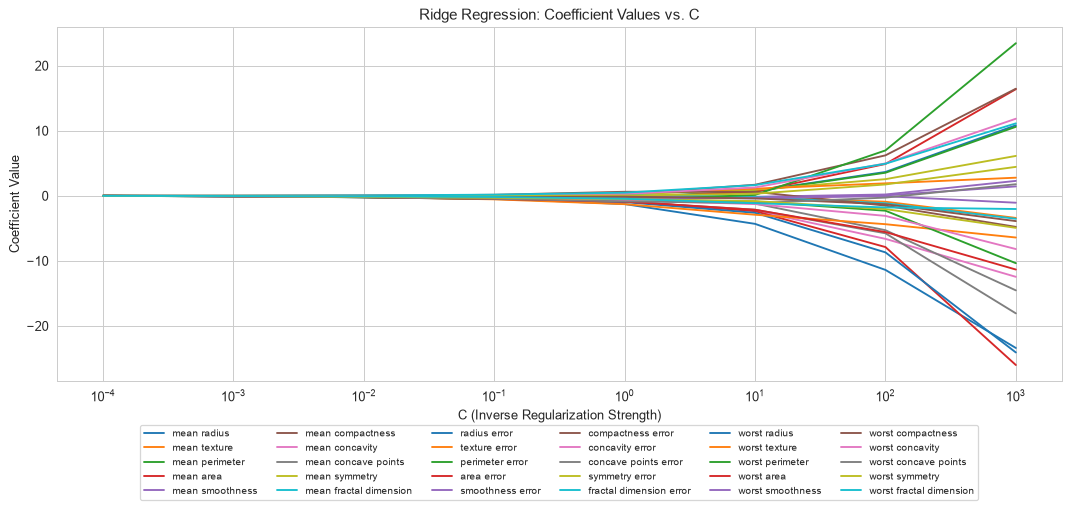

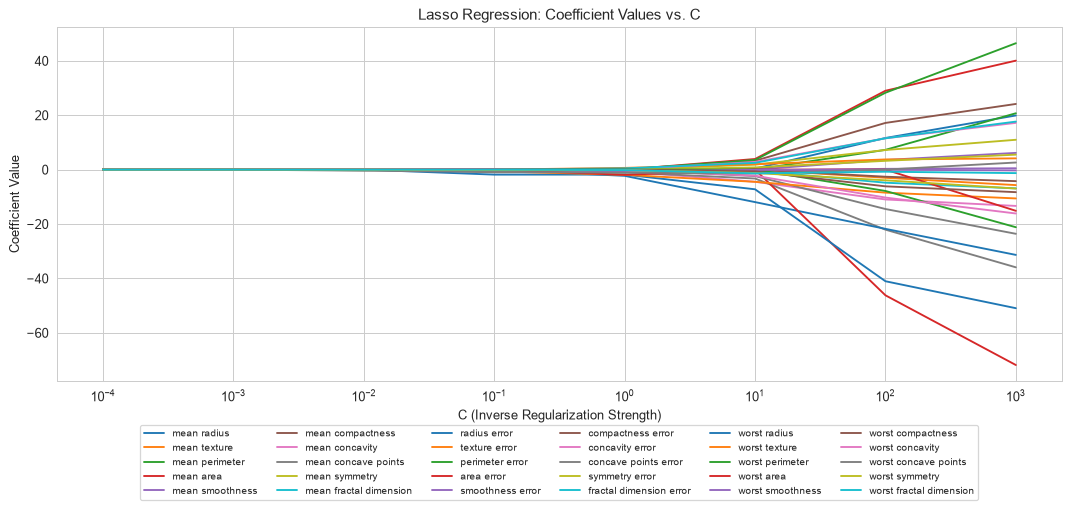

In [11]:
# Coefficient path untuk berbagai nilai C (Ridge)
C_values = np.array([0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000])
coefs_ridge = []
for C in C_values:
    ridge_model = LogisticRegression(l1_ratio=0, solver='liblinear', C=C)
    ridge_model.fit(X_train, y_train)
    coefs_ridge.append(ridge_model.coef_[0])

plt.figure(figsize=(12, 6))
for i in range(X.shape[1]):
    plt.plot(C_values, [coef[i] for coef in coefs_ridge], label=feature_names[i])
plt.xscale('log')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Coefficient Value')
plt.title('Ridge Regression: Coefficient Values vs. C')
plt.legend(bbox_to_anchor=(0.5, -0.35), ncol=6, loc='lower center', fontsize=8)
plt.tight_layout()
plt.show()

# Coefficient path (Lasso)
coefs_lasso = []
for C in C_values:
    lasso_model = LogisticRegression(l1_ratio=1, solver='liblinear', C=C)
    lasso_model.fit(X_train, y_train)
    coefs_lasso.append(lasso_model.coef_[0])

plt.figure(figsize=(12, 6))
for i in range(X.shape[1]):
    plt.plot(C_values, [coef[i] for coef in coefs_lasso], label=feature_names[i])
plt.xscale('log')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Coefficient Value')
plt.title('Lasso Regression: Coefficient Values vs. C')
plt.legend(bbox_to_anchor=(0.5, -0.35), ncol=6, loc='lower center', fontsize=8)
plt.tight_layout()
plt.show()

**Interpretasi:**

- **Ridge path:** semua 30 koefisien bergerak mulus bersamaan dari ≈0 (C = $10^{-4}$) menuju nilai yang makin besar; tidak ada yang tepat nol. Saat C sangat besar (penalti hampir hilang) beberapa koefisien membesar hingga |β| ≈ 26 — tanda varians tinggi akibat fitur yang saling berkorelasi.
- **Lasso path:** untuk C ≤ 0.001 semua koefisien **tepat nol**; fitur kemudian "masuk" satu per satu saat C membesar. Pada C ≥ 10 koefisien meledak (hingga |β| ≈ 72 pada C = 1000, mis. `worst area` dan `mean radius` ke arah negatif besar sementara `mean perimeter` positif besar) — fitur kembar saling meniadakan, gejala overfitting dan multikolinearitas.

In [12]:
# Tambahan: ringkasan numerik path -- jumlah koefisien bukan nol dan akurasi uji untuk tiap C
rows = []
for C, cr, cl in zip(C_values, coefs_ridge, coefs_lasso):
    acc_r = LogisticRegression(l1_ratio=0, solver='liblinear', C=C).fit(X_train, y_train).score(X_test, y_test)
    acc_l = LogisticRegression(l1_ratio=1, solver='liblinear', C=C).fit(X_train, y_train).score(X_test, y_test)
    rows.append({'C': C, 'L2 max|coef|': np.abs(cr).max(), 'L2 test acc': acc_r,
                 'L1 nonzero': int(np.sum(cl != 0)), 'L1 max|coef|': np.abs(cl).max(), 'L1 test acc': acc_l})
display(pd.DataFrame(rows).round(3))

,C,L2 max|coef|,L2 test acc,L1 nonzero,L1 max|coef|,L1 test acc
0,0.000,0.014,0.918,0,0.000,0.392
1,0.001,0.077,0.936,0,0.000,0.392
2,0.010,0.234,0.947,2,0.396,0.918
3,0.100,0.546,0.982,7,1.842,0.965
4,1.000,1.287,0.982,15,2.290,0.977
5,10.000,4.313,0.977,23,11.942,0.965
6,100.000,11.391,0.959,28,46.214,0.947
7,1000.000,26.008,0.947,30,71.845,0.947


**Interpretasi:**

- Tabel memperlihatkan *trade-off* bias–varians dengan jelas. Penalti terlalu kuat: L1 dengan C ≤ 0.001 memiliki **0 fitur** dan accuracy **0.392** = 67/171, yaitu proporsi *malignant* di data uji. Semua koefisien nol dan `liblinear` ikut memenalti intersep sehingga intersep ≈ 0, probabilitas setiap sampel ≈ 0.5, dan model memprediksi kelas 0 untuk semua sampel — bahkan lebih buruk daripada menebak kelas mayoritas; L2 dengan C = 0.0001 masih 0.918 karena semua fitur tetap berkontribusi sedikit.
- Titik optimum ada di tengah: L2 terbaik pada C = 0.1–1 (**0.982**), L1 terbaik pada C = 1 (**0.977**, 15 fitur). Penalti terlalu lemah (C = 1000) menurunkan keduanya ke **0.947** dengan koefisien sangat besar — overfitting.
- Kesimpulan praktis: C harus dipilih dengan validasi silang (mis. `LogisticRegressionCV`), bukan pada data uji seperti tabel ilustrasi ini.

## 6.4 Konsep Klasifikasi Multilabel

**Teori:**

**Multiclass vs multilabel.** Pada *multiclass* setiap sampel memiliki **tepat satu** label dari $K$ kelas. Pada *multilabel* setiap sampel dapat memiliki **nol, satu, atau beberapa** label sekaligus — misalnya artikel berita yang bertopik "politik" dan "ekonomi", atau citra yang berisi "mobil" dan "pejalan kaki". Target direpresentasikan sebagai matriks biner $Y\in\{0,1\}^{n\times L}$ (*label indicator matrix*).

**Binary Relevance (OvR untuk multilabel).** Pendekatan paling sederhana: latih $L$ klasifikator biner independen, satu untuk setiap kolom label — persis yang dilakukan loop di resep ini, dan setara dengan `OneVsRestClassifier` atau `MultiOutputClassifier` pada target 2D. Kelemahannya: **korelasi antar-label diabaikan**. Alternatif yang memodelkan ketergantungan label antara lain `ClassifierChain` (prediksi label sebelumnya dijadikan fitur untuk label berikutnya) dan metode *label powerset*.

**Metrik multilabel.**
- **Subset accuracy** (`accuracy_score` pada target multilabel): sampel dihitung benar hanya jika **seluruh** vektor labelnya cocok persis. Metrik ini sangat ketat — dengan 5 label, satu kesalahan saja membuat sampel dianggap salah.
- **Hamming loss**: proporsi pasangan (sampel, label) yang salah, $\frac{1}{nL}\sum_{i,l}\mathbb 1[\hat y_{il}\ne y_{il}]$. Lebih "lunak" dan informatif.
- **Precision/recall/F1 per label** dan rata-ratanya: *micro* (gabungkan semua TP/FP/FN lalu hitung), *macro* (rata-rata per label), *weighted*, dan *samples* (hitung per sampel lalu rata-ratakan).

**Analisis co-occurrence.** Matriks $Y^\top Y$ berukuran $L\times L$: elemen diagonal $(l,l)$ = frekuensi label $l$, elemen $(l,m)$ = berapa kali label $l$ dan $m$ muncul bersama. Menormalkan tiap baris dengan diagonal memberikan $P(\text{label } m \mid \text{label } l)$ — berguna untuk melihat ketergantungan label yang diabaikan oleh Binary Relevance.

**Dataset sintetis.** `make_multilabel_classification` membangkitkan sampel dengan model generatif: jumlah label tiap sampel ~ Poisson(`n_labels`), dan fitur berupa *count* (seperti frekuensi kata pada dokumen) yang diambil dari distribusi multinomial bergantung label.

In [13]:
# Dataset multilabel sintetis: 1000 sampel, 20 fitur, 5 label, rata-rata 2 label per sampel
X, y = make_multilabel_classification(n_samples=1000, n_features=20, n_classes=5,
                                      n_labels=2, random_state=2024)
df = pd.DataFrame(X, columns=[f'feature_{i}' for i in range(X.shape[1])])
df['target'] = list(y)
display(df.head())
print('Bentuk y:', y.shape, '| rata-rata label per sampel:', y.sum(axis=1).mean().round(2))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,target
0,1.0,2.0,2.0,2.0,4.0,4.0,5.0,0.0,6.0,2.0,...,0.0,2.0,2.0,1.0,2.0,0.0,2.0,6.0,5.0,"[0, 1, 0, 0, 0]"
1,4.0,2.0,1.0,1.0,1.0,3.0,2.0,5.0,2.0,4.0,...,4.0,4.0,2.0,3.0,1.0,2.0,4.0,1.0,3.0,"[0, 0, 0, 0, 0]"
2,1.0,4.0,1.0,1.0,4.0,4.0,6.0,2.0,4.0,4.0,...,5.0,2.0,1.0,1.0,3.0,1.0,5.0,4.0,3.0,"[0, 1, 1, 0, 0]"
3,0.0,0.0,0.0,6.0,1.0,2.0,0.0,5.0,6.0,0.0,...,5.0,3.0,2.0,3.0,2.0,0.0,4.0,0.0,2.0,"[0, 0, 1, 0, 0]"
4,4.0,3.0,0.0,1.0,6.0,6.0,2.0,0.0,2.0,1.0,...,2.0,1.0,2.0,3.0,2.0,3.0,3.0,5.0,3.0,"[1, 1, 0, 0, 1]"


Bentuk y: (1000, 5) | rata-rata label per sampel: 1.9


In [14]:
# Melatih satu model biner untuk setiap label (Binary Relevance)
models = []
y_pred_all = []
for i in range(y_train.shape[1]):
    model = LogisticRegression(solver='liblinear')
    model.fit(X_train, y_train[:, i])
    models.append(model)
    y_pred_all.append(model.predict(X_test))

# Susun prediksi kembali menjadi matriks (n_samples, n_labels)
y_pred = np.array(y_pred_all).T

# Evaluasi
accuracy = accuracy_score(y_test, y_pred)      # subset accuracy
report = pd.DataFrame(classification_report(y_test, y_pred, zero_division=1, output_dict=True)).transpose()
print(f'Subset accuracy (exact match): {accuracy:.3f}')
print(f'Hamming loss                 : {hamming_loss(y_test, y_pred):.3f}')
print('Classification Report:')
display(style_report(report))

# Tambahan: loop manual setara dengan OneVsRestClassifier / MultiOutputClassifier
ovr_ml = OneVsRestClassifier(LogisticRegression(solver='liblinear')).fit(X_train, y_train)
mo_ml = MultiOutputClassifier(LogisticRegression(solver='liblinear')).fit(X_train, y_train)
print('Prediksi identik dengan OneVsRestClassifier :', np.array_equal(ovr_ml.predict(X_test), y_pred))
print('Prediksi identik dengan MultiOutputClassifier:', np.array_equal(mo_ml.predict(X_test), y_pred))

Subset accuracy (exact match): 0.340
Hamming loss                 : 0.209
Classification Report:


,precision,recall,f1-score,support
0,0.808,0.813,0.811,166
1,0.801,0.845,0.823,181
2,0.674,0.333,0.446,93
3,0.750,0.176,0.286,34
4,0.575,0.477,0.522,88
micro avg,0.757,0.653,0.701,562
macro avg,0.722,0.529,0.577,562
weighted avg,0.744,0.653,0.677,562
samples avg,0.787,0.782,0.680,562


Prediksi identik dengan OneVsRestClassifier : True
Prediksi identik dengan MultiOutputClassifier: True


**Interpretasi:**

- Setiap sampel rata-rata memiliki **1.9 label** dari 5 label; beberapa sampel bahkan tidak memiliki label sama sekali (vektor `[0, 0, 0, 0, 0]`).
- **Subset accuracy hanya 0.340**: hanya 34% sampel uji yang kelima labelnya tebakan persis benar. Sebaliknya **Hamming loss 0.209** berarti ~79% keputusan label individual sudah benar. Kontras ini menunjukkan mengapa subset accuracy sangat ketat untuk masalah multilabel.
- Performa per label sangat timpang: label 0 dan 1 (frekuen, ~55–60% sampel) memiliki F1 ≈ **0.81–0.82**, sedangkan label 3 (hanya 34 sampel positif di data uji) memiliki recall **0.176** dan F1 **0.286**. Model cenderung memprediksi "tidak" untuk label yang jarang — efek ketidakseimbangan kelas pada tiap sub-masalah biner. Rata-rata *micro* F1 0.701 (didominasi label frekuen) lebih tinggi daripada *macro* F1 0.577 (semua label setara).
- Loop manual menghasilkan prediksi **identik** dengan `OneVsRestClassifier` dan `MultiOutputClassifier`, membuktikan bahwa ketiganya adalah implementasi *Binary Relevance* yang sama.

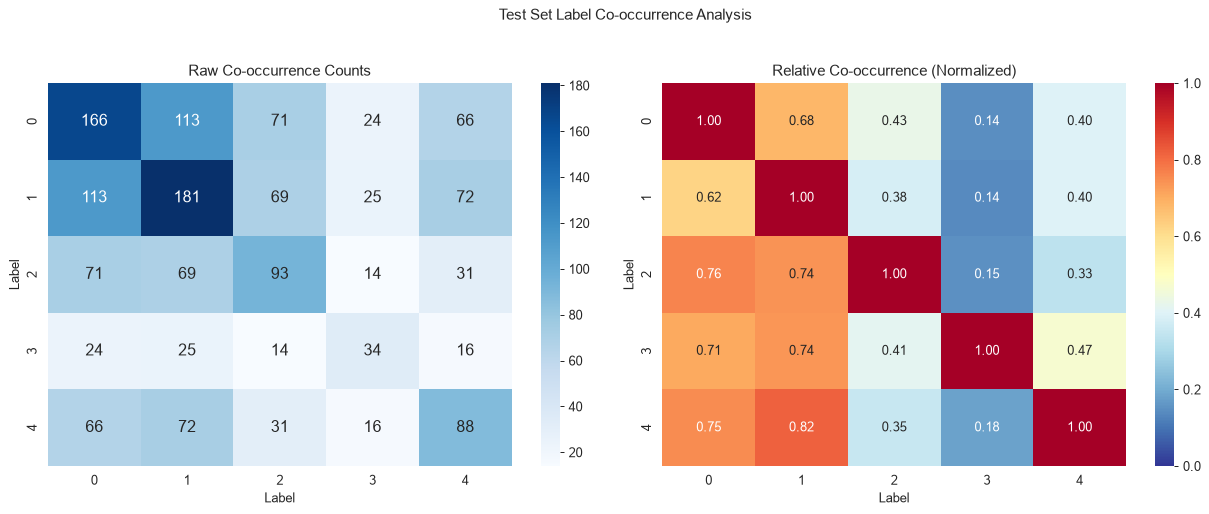


Label Statistics:
Total samples: 300

Label frequencies:
Label 0: 166 samples (55.3%)
Label 1: 181 samples (60.3%)
Label 2: 93 samples (31.0%)
Label 3: 34 samples (11.3%)
Label 4: 88 samples (29.3%)

Most common label combinations:
Combination [0 0 0 0 0]: 52 samples (17.3%)
Combination [0 1 0 0 0]: 34 samples (11.3%)
Combination [1 1 0 0 0]: 28 samples (9.3%)
Combination [1 1 1 0 0]: 25 samples (8.3%)
Combination [1 1 0 0 1]: 24 samples (8.0%)


In [15]:
# Visualisasi co-occurrence label
def plot_label_cooccurrence(y, title="Label Co-occurrence Analysis"):
    # Hitungan co-occurrence mentah
    cooccurrence = y.T @ y

    # Co-occurrence relatif: baris l dibagi frekuensi label l -> P(label m | label l)
    diag = np.diag(cooccurrence)
    relative_cooccurrence = cooccurrence / diag[:, None]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
    sns.heatmap(cooccurrence, annot=True, fmt='d', cmap='Blues', ax=ax1, annot_kws={"fontsize": 13})
    ax1.set_title('Raw Co-occurrence Counts')
    ax1.set_xlabel('Label')
    ax1.set_ylabel('Label')

    sns.heatmap(relative_cooccurrence, annot=True, fmt='.2f', cmap='RdYlBu_r', ax=ax2,
                annot_kws={"fontsize": 10}, vmin=0, vmax=1)
    ax2.set_title('Relative Co-occurrence (Normalized)')
    ax2.set_xlabel('Label')
    ax2.set_ylabel('Label')

    plt.suptitle(title, y=1.03)
    plt.tight_layout()
    plt.show()

    print("\nLabel Statistics:")
    print(f"Total samples: {len(y)}")
    print("\nLabel frequencies:")
    for i in range(y.shape[1]):
        count = y[:, i].sum()
        print(f"Label {i}: {count} samples ({count / len(y) * 100:.1f}%)")

    print("\nMost common label combinations:")
    combos, counts = np.unique(y, axis=0, return_counts=True)
    sorted_idx = np.argsort(-counts)
    for combo, count in zip(combos[sorted_idx][:5], counts[sorted_idx][:5]):
        print(f"Combination {combo}: {count} samples ({count / len(y) * 100:.1f}%)")

plot_label_cooccurrence(y_test, "Test Set Label Co-occurrence Analysis")

**Interpretasi:**

- Diagonal matriks mentah adalah frekuensi label pada 300 sampel uji: label 1 (181) dan label 0 (166) paling sering, label 3 paling jarang (34).
- Matriks relatif dibaca per baris sebagai $P(\text{kolom}\mid\text{baris})$ — tidak simetris. Contoh: $P(\text{label 1}\mid\text{label 4}) = 0.82$ dan $P(\text{label 0}\mid\text{label 2}) = 0.76$, sedangkan sebaliknya $P(\text{label 4}\mid\text{label 1}) = 0.40$. Label yang jarang hampir selalu muncul bersama label 0 dan 1, sebagian karena label 0/1 memang muncul di lebih dari separuh sampel.
- Kombinasi paling umum adalah **tanpa label** (17.3%), lalu hanya label 1 (11.3%), label {0,1} (9.3%), {0,1,2} (8.3%), dan {0,1,4} (8.0%). Ketergantungan seperti ini diabaikan oleh Binary Relevance; metode seperti `ClassifierChain` dapat memanfaatkannya untuk meningkatkan subset accuracy.

## 6.5 Metrik Evaluasi Model

**Teori:**

Dengan confusion matrix biner (TP, FP, FN, TN):

$$
\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN},\quad
\text{Precision}=\frac{TP}{TP+FP},\quad
\text{Recall (TPR)}=\frac{TP}{TP+FN},\quad
F_1=\frac{2\cdot\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}} .
$$

- **Accuracy** menyesatkan bila kelas tidak seimbang (memprediksi kelas mayoritas saja sudah tinggi).
- **Precision** penting bila *false positive* mahal (mis. menandai email penting sebagai spam).
- **Recall** penting bila *false negative* mahal (mis. melewatkan tumor ganas). Dalam medis, *recall* kelas ganas sering lebih penting daripada akurasi total.
- **F1** menyeimbangkan keduanya; varian $F_\beta$ memberi bobot $\beta$ lebih pada recall.

Ingat: `precision_score`/`recall_score` memakai `pos_label=1`, yaitu **benign** di dataset ini.

**Ambang (threshold) dan kurva ROC.** `predict` memakai ambang 0.5 pada $P(y=1)$. Dengan menggeser ambang $t$ dari 1 ke 0 kita memperoleh pasangan

$$
\text{FPR}(t)=\frac{FP}{FP+TN},\qquad \text{TPR}(t)=\frac{TP}{TP+FN},
$$

yang membentuk kurva **ROC** (*Receiver Operating Characteristic*). Diagonal $\text{TPR}=\text{FPR}$ adalah klasifikator acak. **AUC** (luas di bawah kurva ROC) bernilai 0.5 (acak) sampai 1 (sempurna), dan memiliki tafsiran probabilistik: **AUC = peluang bahwa sampel positif acak memperoleh skor lebih tinggi daripada sampel negatif acak**. AUC tidak bergantung pada ambang dan skala probabilitas (hanya urutan/peringkat skor). Untuk data sangat tidak seimbang, kurva *precision–recall* sering lebih informatif.

Fungsi `roc_curve` mengembalikan `fpr`, `tpr`, `thresholds`; `auc` menghitung luas dengan aturan trapesium (setara `roc_auc_score`).

In [16]:
# Memuat ulang Breast Cancer, split 70:30 (tanpa scaling, sesuai buku)
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

Accuracy 0.94
Precision 0.94
Recall 0.95
F1 Score 0.95
ROC AUC 0.99
Classification Report:


,precision,recall,f1-score,support
0,0.924,0.910,0.917,67
1,0.943,0.952,0.947,104
accuracy,0.936,0.936,0.936,1
macro avg,0.934,0.931,0.932,171
weighted avg,0.936,0.936,0.936,171


Confusion matrix [[TN FP] [FN TP]] (positif = benign):
 [[61  6]
 [ 5 99]]


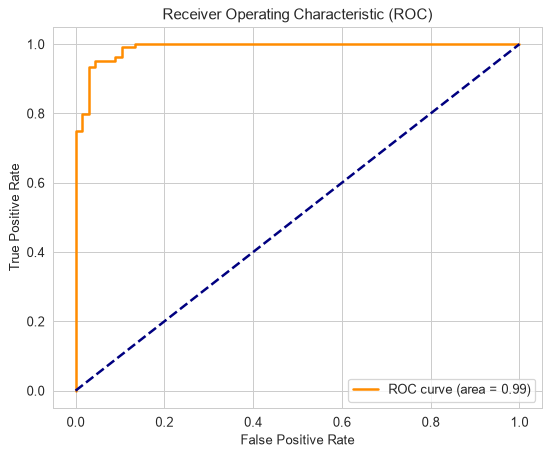

In [17]:
model = LogisticRegression(solver='liblinear')
model.fit(X_train, y_train)

# Label prediksi dan probabilitas kelas positif (benign)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Metrik evaluasi
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
report = pd.DataFrame(classification_report(y_test, y_pred, zero_division=1, output_dict=True)).transpose()

print(f"Accuracy {accuracy:.2f}")
print(f"Precision {precision:.2f}")
print(f"Recall {recall:.2f}")
print(f"F1 Score {f1:.2f}")
print(f"ROC AUC {roc_auc:.2f}")
print("Classification Report:")
display(style_report(report))
print('Confusion matrix [[TN FP] [FN TP]] (positif = benign):\n', confusion_matrix(y_test, y_pred))

# Kurva ROC
plt.figure(figsize=(7, 5.5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

**Interpretasi:**

- Dengan `liblinear` pada fitur **tanpa scaling** (171 sampel uji): accuracy **0.94**, precision **0.94**, recall **0.95**, F1 **0.95** (untuk kelas positif = benign), dan **ROC AUC 0.99**.
- Confusion matrix: 61 dari 67 tumor ganas terdeteksi (6 ganas lolos sebagai jinak, recall malignant 0.910) dan 99 dari 104 tumor jinak benar (5 *false alarm*).
- AUC 0.99 jauh lebih tinggi daripada accuracy 0.94: **peringkat** skor model hampir sempurna (99% pasangan acak ganas–jinak diurutkan benar), tetapi ambang 0.5 belum tentu ambang terbaik. Kurva ROC naik tajam ke dekat pojok kiri atas, jauh di atas diagonal klasifikator acak.

In [18]:
# Tambahan: pengaruh threshold terhadap precision dan recall kelas malignant (kelas 0)
rows = []
for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pred_t = (y_prob >= t).astype(int)           # 1 = benign
    rows.append({'threshold P(benign)': t,
                 'accuracy': accuracy_score(y_test, pred_t),
                 'recall malignant': recall_score(y_test, pred_t, pos_label=0),
                 'precision malignant': precision_score(y_test, pred_t, pos_label=0, zero_division=0)})
display(pd.DataFrame(rows).round(3))

# Bandingkan: model yang sama dengan standardisasi fitur
pipe = make_pipeline(StandardScaler(), LogisticRegression(solver='liblinear')).fit(X_train, y_train)
fpr_s, tpr_s, _ = roc_curve(y_test, pipe.predict_proba(X_test)[:, 1])
print(f'Dengan StandardScaler -> accuracy = {pipe.score(X_test, y_test):.3f}, AUC = {auc(fpr_s, tpr_s):.4f}')
print(f'Tanpa scaling         -> accuracy = {accuracy:.3f}, AUC = {roc_auc:.4f}')

,threshold P(benign),accuracy,recall malignant,precision malignant
0,0.1,0.924,0.806,1.000
1,0.3,0.947,0.881,0.983
2,0.5,0.936,0.910,0.924
3,0.7,0.942,0.955,0.901
4,0.9,0.877,0.970,0.774


Dengan StandardScaler -> accuracy = 0.982, AUC = 0.9994
Tanpa scaling         -> accuracy = 0.936, AUC = 0.9892


**Interpretasi:**

- Tabel ambang memperlihatkan *trade-off* precision–recall untuk kelas **malignant**: menaikkan ambang P(benign) dari 0.5 ke **0.7** menaikkan recall malignant dari 0.910 menjadi **0.955** (lebih sedikit kanker yang terlewat) dengan precision turun ke 0.901, sementara accuracy justru sedikit naik (0.942). Pada ambang 0.9 recall malignant mencapai 0.970 tetapi precision anjlok ke 0.774. Dalam konteks medis, ambang di atas 0.5 sering lebih masuk akal.
- Menambahkan `StandardScaler` (pipeline) menaikkan accuracy dari **0.936 → 0.982** dan AUC dari **0.9892 → 0.9994**. Tanpa scaling, penalti L2 default dan solver liblinear bekerja pada fitur yang skalanya berbeda ribuan kali lipat sehingga solusi kurang optimal.

## Latihan

Bagian ini mereproduksi tiga latihan di akhir chapter beserta solusinya (dari notebook *Exercise Solutions*): (1) regresi logistik L1 pada Breast Cancer, (2) regresi logistik multinomial pada Iris, dan (3) visualisasi batas keputusan pada data sintetis 2 dimensi.

**Teori singkat:** latihan ini menguji tiga hal yang sudah dibahas — efek penalti L1 tanpa standardisasi, softmax untuk masalah multikelas, dan sifat **linear** batas keputusan regresi logistik ($\boldsymbol\beta^\top\mathbf x+\beta_0=0$ adalah garis lurus di ruang 2D).

### Exercise 1: Logistic Regression dengan Regularisasi L1 (Lasso)

In [19]:
data = load_breast_cancer()
X = data.data
y = data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Lasso (L1) -- di solusi buku: penalty='l1'
lasso_model = LogisticRegression(l1_ratio=1, solver='liblinear', max_iter=10000, C=0.1)
lasso_model.fit(X_train, y_train)

y_pred_lasso = lasso_model.predict(X_test)
accuracy_lasso = accuracy_score(y_test, y_pred_lasso)
print(f"Lasso Model Accuracy: {accuracy_lasso:.2f}")

# Tambahan: fitur yang bertahan (tanpa scaling!)
nz = lasso_model.coef_[0] != 0
print(f'Koefisien bukan nol: {nz.sum()}/30 ->', data.feature_names[nz].tolist())

Lasso Model Accuracy: 0.95
Koefisien bukan nol: 7/30 -> ['mean perimeter', 'mean area', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area']


**Interpretasi:**

- Lasso (C = 0.1) **tanpa standardisasi** memperoleh accuracy **0.95** — sedikit di bawah versi terstandardisasi pada 6.3 (0.965).
- Yang lebih menarik adalah fitur yang dipilih: 7 fitur yang bertahan kini didominasi **fitur berskala besar** (`mean area`, `worst area`, `mean perimeter`, `worst perimeter`, `area error`, ...), bukan fitur cekungan yang terpilih saat data distandardisasi. Fitur bernilai ratusan–ribuan hanya butuh koefisien kecil untuk berpengaruh sehingga "murah" di bawah penalti L1, sedangkan fitur berskala kecil (mis. *smoothness* ~0.1) butuh koefisien besar dan karenanya dibuang. Seleksi fitur L1 tanpa scaling mencerminkan **satuan**, bukan kepentingan fitur.

### Exercise 2: Evaluasi Multinomial Logistic Regression

In [20]:
iris = load_iris()
X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

multinomial_model = LogisticRegression(solver='lbfgs', max_iter=1000)
multinomial_model.fit(X_train, y_train)

y_pred_multinomial = multinomial_model.predict(X_test)
accuracy_multinomial = accuracy_score(y_test, y_pred_multinomial)
print(f"Multinomial Model Accuracy: {accuracy_multinomial:.2f}")

# Tambahan: confusion matrix dan contoh probabilitas softmax (tiap baris berjumlah 1)
print('Confusion matrix:\n', confusion_matrix(y_test, y_pred_multinomial))
display(pd.DataFrame(multinomial_model.predict_proba(X_test[:5]), columns=iris.target_names).round(3))

Multinomial Model Accuracy: 0.93
Confusion matrix:
 [[18  0  0]
 [ 0 11  1]
 [ 0  2 13]]


,setosa,versicolor,virginica
0,0.982,0.018,0.000
1,0.980,0.020,0.000
2,0.008,0.818,0.175
3,0.003,0.515,0.483
4,0.969,0.031,0.000


**Interpretasi:**

- Multinomial logistic regression pada Iris mencapai accuracy **0.93** (42/45), sama dengan resep 6.2. Confusion matrix: setosa 18/18 benar, 1 versicolor diprediksi virginica, dan 2 virginica diprediksi versicolor.
- Tabel probabilitas softmax menunjukkan tiap baris berjumlah 1. Sampel ke-4 (indeks 3) adalah contoh kasus perbatasan: P(versicolor) = 0.515 vs P(virginica) = 0.483 — model hampir ragu sepenuhnya, cocok dengan tumpang tindih kedua kelas pada pairplot.

### Exercise 3: Visualisasi Hasil Logistic Regression (Decision Boundary)

Test accuracy: 0.897
Batas keputusan: -0.183 + 2.283*x1 + -0.154*x2 = 0


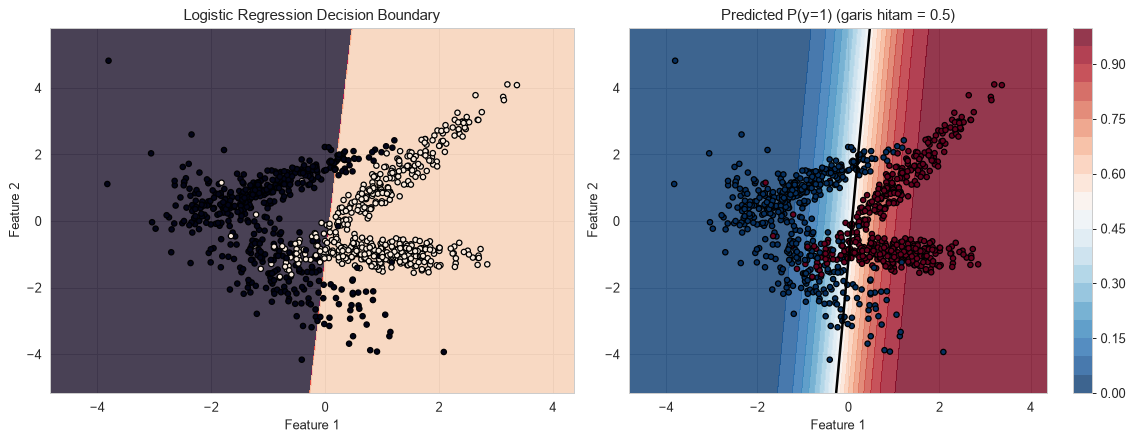

In [21]:
# Dataset sintetis 2 fitur untuk klasifikasi biner
X, y = make_classification(n_samples=1000, n_features=2, n_classes=2, n_informative=2,
                           n_redundant=0, random_state=2024)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

logistic_model = LogisticRegression()
logistic_model.fit(X_train, y_train)
print(f'Test accuracy: {logistic_model.score(X_test, y_test):.3f}')
b0, (b1, b2) = logistic_model.intercept_[0], logistic_model.coef_[0]
print(f'Batas keputusan: {b0:.3f} + {b1:.3f}*x1 + {b2:.3f}*x2 = 0')

# Mesh grid untuk plot batas keputusan
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Prediksi kelas di seluruh grid (buku); ditambah probabilitas untuk panel kedua
Z = logistic_model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
P = logistic_model.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].contourf(xx, yy, Z, alpha=0.8)
axes[0].scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o', s=18)
axes[0].set_title("Logistic Regression Decision Boundary")
cs = axes[1].contourf(xx, yy, P, levels=20, cmap='RdBu_r', alpha=0.8)
axes[1].contour(xx, yy, P, levels=[0.5], colors='k', linewidths=2)
axes[1].scatter(X[:, 0], X[:, 1], c=y, cmap='RdBu_r', edgecolors='k', marker='o', s=18)
axes[1].set_title("Predicted P(y=1) (garis hitam = 0.5)")
fig.colorbar(cs, ax=axes[1])
for ax in axes:
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
plt.tight_layout()
plt.show()

**Interpretasi:**

- Pada data sintetis 2D (1000 sampel), model mencapai accuracy uji **0.897**. Persamaan batas keputusannya $-0.183 + 2.283x_1 - 0.154x_2 = 0$: koefisien $x_1$ jauh lebih besar daripada $x_2$, sehingga batasnya berupa **garis lurus yang hampir vertikal** di sekitar $x_1 \approx 0.08$ — praktis hanya fitur 1 yang membedakan kelas pada data ini.
- Panel kanan memperlihatkan bahwa regresi logistik tidak hanya memberi label tetapi juga **gradasi probabilitas**: probabilitas berubah mulus (sigmoid) saat menjauhi garis 0.5, dan ~10% sampel yang salah adalah titik-titik dari kedua kelas yang saling bertumpuk di dekat batas. Untuk pola yang membutuhkan batas melengkung, regresi logistik perlu diberi fitur non-linear (mis. `PolynomialFeatures`) atau diganti model non-linear.

## Ringkasan Chapter 6

1. **Regresi logistik** memodelkan $P(y=1\mid\mathbf x)=\sigma(\beta_0+\boldsymbol\beta^\top\mathbf x)$, linear terhadap *log-odds*, dan dilatih dengan meminimalkan log-loss (konveks, diselesaikan iteratif). Koefisien ditafsirkan sebagai perubahan log-odds atau *odds ratio* $e^{\beta_j}$, tetapi tafsiran ini rapuh bila fitur tidak diskalakan dan saling berkorelasi. Pada Breast Cancer model dasar mencapai accuracy 0.95.
2. **Multiclass:** One-vs-Rest melatih $K$ model biner terpisah, sedangkan multinomial (softmax) mengoptimasi semua kelas bersama. Pada Iris accuracy keduanya mirip (0.956 vs 0.933, beda 1 sampel), tetapi multinomial menghasilkan probabilitas lebih baik (log-loss 0.17 vs 0.32) dan batas keputusan yang lebih masuk akal untuk kelas "tengah" (0.911 vs 0.844 pada 2 fitur petal). Di scikit-learn 1.9 multinomial adalah default; OvR dibuat eksplisit dengan `OneVsRestClassifier`.
3. **Regularisasi** dikendalikan oleh $C$ (kebalikan kekuatan penalti) dan, sejak 1.8, jenisnya oleh `l1_ratio` (0 = L2, 1 = L1). L2 menyusutkan semua koefisien (Ridge, accuracy 0.982), L1 menghasilkan model sparse (7/30 fitur, accuracy 0.965). *Coefficient path* dan tabel per-C menunjukkan *trade-off* bias–varians: penalti terlalu kuat → underfitting, terlalu lemah → koefisien meledak. Standardisasi fitur wajib, dan seleksi fitur L1 tanpa scaling hanya mencerminkan satuan.
4. **Multilabel** ditangani dengan *Binary Relevance* (satu model biner per label, setara `OneVsRestClassifier`/`MultiOutputClassifier`). Subset accuracy sangat ketat (0.34) dibanding Hamming loss (0.21); label jarang memiliki recall rendah, dan analisis co-occurrence mengungkap ketergantungan label yang diabaikan pendekatan ini.
5. **Metrik evaluasi:** accuracy saja tidak cukup; precision, recall, F1 per kelas dan ROC/AUC memberikan gambaran lengkap. AUC (0.99) mengukur kualitas peringkat tanpa bergantung ambang, sedangkan memindahkan ambang keputusan memungkinkan menukar precision dengan recall sesuai biaya kesalahan (mis. recall kelas ganas naik ke 0.955 pada ambang 0.7).
6. **Latihan** menegaskan: L1 tanpa scaling memilih fitur berskala besar, softmax memberikan probabilitas yang berjumlah 1 dan menunjukkan kasus ragu di perbatasan kelas, dan batas keputusan regresi logistik selalu berupa garis/hyperplane.

**Pesan utama:** regresi logistik adalah *baseline* klasifikasi yang kuat dan dapat ditafsirkan — standardisasi fitur, gunakan multinomial untuk kelas eksklusif, pilih jenis dan kekuatan regularisasi ($C$, `l1_ratio`) dengan validasi silang, dan evaluasi dengan metrik serta ambang yang sesuai dengan biaya kesalahan pada masalah nyata.